In [ ]:
import pandas as pd
import scipy.stats
from scipy.ndimage import gaussian_filter1d
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
import umap
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys

# from BWM.Notebooks.DensityMatching import active_lambda
active_lambda = 0.1 # Default value if not imported
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *

def soft_median(x, temperature=0.1):
    """
    Computes a differentiable median across both the 'k' and 't' dimensions.

    Args:
        x: Tensor of shape (k, t, n)
        temperature: Controls sharpness. Lower values (e.g., 0.01) are closer
                     to the true median but yield sharper gradients.

    Returns:
        Tensor of shape (n,) representing the global median for each feature.
    """
    k, t, n = x.shape

    # 1. Flatten k and t into a single dimension
    # x_flat shape: (k * t, n)
    x_flat = x.reshape(k * t, n)

    # 2. Compute pairwise distances along the combined (k*t) axis for each feature
    # x_flat.unsqueeze(1) shape: (k*t, 1, n)
    # x_flat.unsqueeze(0) shape: (1, k*t, n)
    # dists shape: (k*t, k*t, n)
    dists = torch.abs(x_flat.unsqueeze(1) - x_flat.unsqueeze(0))

    # 3. Sum distances over one of the (k*t) axes to get centrality scores
    # sum_dists shape: (k*t, n)
    sum_dists = dists.sum(dim=1)

    # 4. Apply Softmax over the combined (k*t) dimension
    # weights shape: (k*t, n)
    weights = torch.softmax(-sum_dists / temperature, dim=0)

    # 5. Compute the weighted sum across the combined axis
    # Resulting shape: (n,)
    return (x_flat * weights).sum(dim=0)

def get_curvature(model, u, dt, steps):
    """
    Computes curvature for each neuron at each time step and trial.
    Curvature = (h_dot_i)^2 * f''(h_i)
    where h_i is the pre-activation input to neuron i.
    """

    y = model(u, dt, steps)
    input = model.input_layer(u).unsqueeze(1).expand(-1, steps, -1)
    h = model.recurrent_layer(y) + input

    # 3. Compute f''(h) for softplus
    beta = model.beta
    f_prime = torch.sigmoid(beta * h)
    f_double_prime = beta * f_prime * (1 - f_prime)

    # 4. Compute y_dot analytically
    y_dot = model.alpha * (-y + model.activation(h))

    # 5. Compute h_dot analytically
    h_dot = torch.matmul(y_dot, model.recurrent_layer.weight.t())

    # 6. Compute curvature = (h_dot)^2 * f''(h)
    curvature = (h_dot ** 2) * f_double_prime

    return curvature.detach().numpy(), y_dot.detach().numpy()

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


In [299]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca


pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]
# pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/EID_PseudoResponses/f9860a11-24d3-452e-ab95-39e199f20a93_pseudo_responses.npz')['res_matrix']
X_input = iso_ae_preprocessing(pseudo_response_tensor)



In [300]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    #diff_responses = np.diff(response_tensor_norm, axis=1)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
   # msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

In [301]:
pseudo_response_tensor.shape

(25, 2, 100, 9177)

<Axes: >

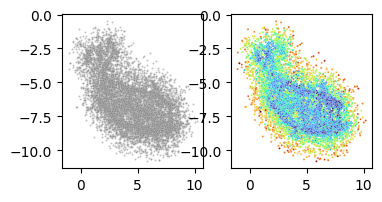

In [302]:
# Plot densmap projection of EID responses
#Figure 1
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])

# First row
#from sklearn.manifold import Isomap
z_neurons = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_input)
#z_neurons = Isomap(n_neighbors=100).fit_transform(X_input)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=2,legend=False,alpha =.5)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = msd_data,ax=ax2,palette='turbo',s=2,legend=False)


In [303]:
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim, beta, bias):
        super(RNN, self).__init__()
        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias
        self.activation = torch.nn.Softplus(beta=self.beta)
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True
        self.input_layer = nn.Linear(self.input_dim, self.n, bias=False)
        self.alpha = .1
    def forward(self, u, dt, steps):
        batch_size = u.shape[0]
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha * dt) * states[:, i, :] + self.alpha *dt * (
                self.activation(self.recurrent_layer(states[:, i, :]) + self.input_layer(u)))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)
        return states


n_neurons = pseudo_response_tensor.shape[3]

net = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/CP_net.pth',weights_only=False,map_location=torch.device('cpu'))

In [304]:
# lr = .0001
# active_lambda=0.01
# bias = 2
# beta = 1
dt = 1
steps = 100
# # n_neurons = pseudo_response_tensor.shape[3]
# # net = RNN(n=n_neurons, input_dim=1, beta=beta, bias=bias).to(device)
u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
# #optimizer = optim.Adam(net.parameters(), lr=lr)
# criterion = nn.MSELoss()
# net.train()
# print("Training RNN...")
# for epoch in range(5000):
#     optimizer.zero_grad()
#     x = net(u.unsqueeze(1), dt, steps)
#     x_reshaped = x.reshape(-1, x.shape[2]).T
#     activity_penalty = torch.std(torch.mean(x_reshaped, dim=1)) + torch.std(torch.std(x_reshaped, dim=1))
#     x_norm = (x_reshaped - torch.mean(x_reshaped, dim=1, keepdim=True)) / (torch.std(x_reshaped, dim=1, keepdim=True) + 1e-8)
#
#     loss = criterion(torch.FloatTensor(X_input).to(device), x_norm) + active_lambda * activity_penalty
#     loss.backward()
#     optimizer.step()
#     if epoch % 10 == 0:
#         print(f"Epoch {epoch}: Loss = {loss.item():.4f}")

<Axes: >

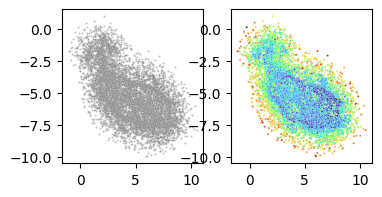

In [306]:
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])

from sklearn.manifold import TSNE
# First row


X_rnn = net(u.unsqueeze(1), dt, 100)
X_rnn = (X_rnn - torch.mean(X_rnn, dim=(0,1), keepdim=True)) / (torch.std(X_rnn, dim=(0,1), keepdim=True) + 1e-8)
X_rnn_reshaped = X_rnn.reshape(-1, X_rnn.shape[2]).T.detach().cpu().numpy()
speed_rnn_original = torch.mean(torch.abs(torch.diff(X_rnn,dim=1)),dim=(0,1)).detach()

z_neurons = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_rnn_reshaped)
sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], color = 'gray',ax=ax1,s=2,legend=False,alpha =.5)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = speed_rnn_original,ax=ax2,palette='turbo',s=2,legend=False)


In [ ]:
X_rnn_reshaped.shape

In [307]:
# Fit MLP model of densmap projections
import torch
import torch.nn as nn
import torch.optim as optim

class TensorTransformer(nn.Module):
    def __init__(self, input_dim, output_dim, dropout_rate=0.):
        super(TensorTransformer, self).__init__()
        # A simple 3-layer architecture with dropout for robustness
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),    # Input layer to hidden layer 1         # Hidden layer 1 t
            nn.ReLU(),
            nn.Linear(64, 64),    # Input layer to hidden layer 1         # Hidden layer 1 t
            nn.ReLU(),    # Non-linear activation  # Dropout for regularization
            nn.Linear(64, output_dim)    # Hidden layer 2 to output layer
        )

    def forward(self, x, noise_std=1):
        # Add Gaussian noise to input during training for better generalization
        if self.training and noise_std > 0:
            noise = torch.randn_like(x) * noise_std
            x = x + noise
        return self.network(x)

epochs = 20000
learning_rate = 0.001

y = net(u = u.unsqueeze(1),dt=dt,steps=100).detach()
z = (y - torch.mean(y,dim=(0,1)))/torch.std(y,dim=(0,1))
x = z.reshape(-1,z.shape[2]).t()

y = torch.FloatTensor(umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(x))


# Initialize model, loss function, and optimizer
densMAPprojector = TensorTransformer(input_dim=x.shape[1], output_dim=2)
criterion = nn.MSELoss()
optimizer = optim.Adam(densMAPprojector.parameters(), lr=learning_rate)

# Put model in training mode
densMAPprojector.train()

for epoch in range(epochs):
    # 1. Forward pass: compute predicted y by passing x to the model
    predictions = densMAPprojector(x)

    # 2. Compute loss
    loss = criterion(predictions, y)

    # 3. Zero gradients, perform a backward pass, and update the weights
    optimizer.zero_grad()  # Clear old gradients
    loss.backward()        # Backpropagation
    optimizer.step()       # Gradient descent step

    # Print progress every 20 epochs
    if (epoch + 1) % 1000 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [1000/20000], Loss: 0.5062
Epoch [2000/20000], Loss: 0.3631
Epoch [3000/20000], Loss: 0.3266
Epoch [4000/20000], Loss: 0.2925
Epoch [5000/20000], Loss: 0.2681
Epoch [6000/20000], Loss: 0.2711
Epoch [7000/20000], Loss: 0.2587
Epoch [8000/20000], Loss: 0.2683
Epoch [9000/20000], Loss: 0.2472
Epoch [10000/20000], Loss: 0.2501
Epoch [11000/20000], Loss: 0.2471
Epoch [12000/20000], Loss: 0.2351
Epoch [13000/20000], Loss: 0.2534
Epoch [14000/20000], Loss: 0.2551
Epoch [15000/20000], Loss: 0.2296
Epoch [16000/20000], Loss: 0.2382
Epoch [17000/20000], Loss: 0.2451
Epoch [18000/20000], Loss: 0.2279
Epoch [19000/20000], Loss: 0.2310
Epoch [20000/20000], Loss: 0.2285


<Axes: xlabel='None', ylabel='None'>

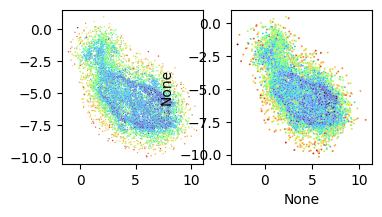

In [308]:
#Figure 1
fig = plt.figure(figsize=(4, 2))
gs = gridspec.GridSpec(1, 2)
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
densMAPprojector.eval()
# First row
X_rnn = net(u = u.unsqueeze(1),dt=dt,steps=100)
X_rnn = (X_rnn - torch.mean(X_rnn,dim = (0,1),keepdim=True))/torch.std(X_rnn,dim = (0,1),keepdim = True)
speed_rnn_original = torch.mean(torch.abs(torch.diff(X_rnn,dim=1)),dim=(0,1)).detach()

X_rnn_reshaped = X_rnn.detach().permute(2, 0, 1).reshape(X_rnn.shape[2], -1)
#z_neurons = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(X_rnn_reshaped)

sns.scatterplot(x = z_neurons[:,0], y= z_neurons[:,1], hue = speed_rnn_original,ax=ax1,palette='turbo',s=1,legend=False)
z_neurons_mimic = densMAPprojector(X_rnn_reshaped).detach()
sns.scatterplot(x = z_neurons_mimic[:,0], y= z_neurons_mimic[:,1], hue = speed_rnn_original,ax=ax2,palette='turbo',s=2,legend=False)



In [309]:
# Retraining


def efficient_variance_explained_svd_vals(responses,top_k):
    x_centered = responses - responses.mean(dim=(0),keepdim=True)
    S = torch.linalg.svdvals(x_centered)
    eigenvalues = S**2
    actual_k = min(top_k,len(eigenvalues))
    return eigenvalues[:actual_k]/eigenvalues.sum()

top_k = 100
steps = 100
# Get eigenvalues for original RNN
y = net(u.unsqueeze(1),dt,steps)
# eigs = torch.sort(torch.real(
#     torch.linalg.eigvals(torch.cov(y.reshape(-1, y.shape[2]).t()))),
#                   descending=True)[0]
#
# target
#target_fve = (eigs/ torch.sum(eigs)).detach()
z = (y - torch.mean(y,dim=(0,1)))/torch.std(y,dim=(0,1))
msd_rnn = torch.mean(torch.abs(torch.diff(z,dim=1)),dim=(0,1))
target_fve = efficient_variance_explained_svd_vals(y.reshape(-1, y.shape[2]).t(),top_k = top_k).detach()

In [354]:

net_contract = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/CP_net.pth',weights_only=False,map_location=torch.device('cpu'))
#net_contract = torch.load('net.pth',weights_only=False,map_location=torch.device('cpu'))
import copy


# 1. Instantiate the cloned architecture

#net_contract = RNN(n=n_neurons, input_dim=1, beta=beta, bias=bias).to(device)
# 2. Copy the state weights into the clone
#net_contract.load_state_dict(copy.deepcopy(net.state_dict()))'

#u = torch.FloatTensor(np.linspace(-1, 1, 3)).to(device)
optimizer = optim.Adam(net_contract.parameters(), lr=.00001)
criterion = nn.MSELoss()
steps = 100

In [355]:
import torch

import torch

# Contraction training

threshold = .025
densMAPprojector.eval()
# Allocate lists for projections and speed
projections = []
speeds = []
prev_projection = None
#curvature_target = fsecond(torch.linspace(0,100,100),shift= 20, scale = 2,height = 3)
for epoch in range(500):
    optimizer.zero_grad()
    x = net_contract(u.unsqueeze(1),dt,steps)


    # Activity penalty
    mean_activities = x.mean(dim=(0, 1))
    activity_penalty = mean_activities.std()

    # Variance penalty
    fve = efficient_variance_explained_svd_vals(x.reshape(-1, x.shape[2]).t(),top_k = top_k)
    variance_penalty = torch.mean((fve-target_fve)**2)
    #variance_penalty = torch.mean(fve[3:])

    # Speed penalty
    z = (x-torch.mean(x,dim=(0,1))) / torch.std(x,dim=(0,1))
    speed = torch.mean(torch.abs(torch.diff(z,dim=1)),dim=(0,1))
    #speed=soft_median(torch.abs(torch.diff(z,dim=1)))

    #speed,_ = soft_median(torch.abs(torch.diff(z,dim=1)).flatten(start_dim=0, end_dim=1),dim=0)
    speed_penalty = torch.mean(speed)

    curr_projection = densMAPprojector(z.reshape(-1,z.shape[2]).t())

    # Change penalty (encourages changes in projections between epochs to decrease)
    if prev_projection is not None:
        change_penalty = nn.MSELoss()(curr_projection, prev_projection)
    else:
        change_penalty = torch.tensor(0.0).to(device)

    # Penalize speed in densmap projection
    
    # Response penalty
    X_rnn_reshaped = X_rnn.detach().permute(2, 0, 1).reshape(X_rnn.shape[2], -1)
    x_reshaped = x.reshape(-1, x.shape[2]).T
    x_norm = (x_reshaped - torch.mean(x_reshaped, dim=1, keepdim=True)) / (torch.std(x_reshaped, dim=1, keepdim=True) + 1e-8)
    response_penalty = nn.MSELoss()(X_rnn_reshaped[speed_rnn_original<.03,:], x_norm[speed_rnn_original<.03,:])

    # Linear mapping penalty (encourages mapping from prev to curr to be linear)
    if prev_projection is not None:
        # We want to find A, b such that curr \approx prev @ A + b
        # Prepare prev with a column of ones for bias
        X = torch.cat([prev_projection, torch.ones(prev_projection.shape[0], 1).to(device)], dim=1)
        Y = curr_projection
        # Solve for A_hat using least squares: X @ A_hat = Y
        # A_hat will have shape (3, 2)
        try:
            A_hat = torch.linalg.lstsq(X, Y).solution
            linear_fit = X @ A_hat
            linear_mapping_penalty = nn.MSELoss()(Y, linear_fit)
        except:
            linear_mapping_penalty = torch.tensor(0.0).to(device)
    else:
        linear_mapping_penalty = torch.tensor(0.0).to(device)

    # Calculate loss and backpropagate
    # Adding change_penalty with a weight that increases toward the end of training
    change_weight = 1 * (epoch / 1000)
    loss =  20*variance_penalty + 1*activity_penalty + 1 * speed_penalty# +0*response_penalty + 0. * linear_mapping_penalty #+ change_weight * change_penalty
    #loss =  activity_penalty
    loss.backward()
    optimizer.step()
    speeds.append(speed.detach())
    projections.append(curr_projection.detach())
    prev_projection = curr_projection.detach()

    if epoch % 1 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f} | variance = {variance_penalty.item():.4f} | active = {activity_penalty.item():.4f} | speed = {speed_penalty.item():.4f} | linear = {linear_mapping_penalty.item():.4f} | change = {change_penalty.item():.4f}   ")


Epoch 0: Loss = 0.1478 | variance = 0.0000 | active = 0.0137 | speed = 0.1341 | linear = 0.0000 | change = 0.0000   
Epoch 1: Loss = 0.1445 | variance = 0.0000 | active = 0.0127 | speed = 0.1318 | linear = 0.0015 | change = 0.0015   
Epoch 2: Loss = 0.1417 | variance = 0.0000 | active = 0.0122 | speed = 0.1295 | linear = 0.0015 | change = 0.0016   
Epoch 3: Loss = 0.1392 | variance = 0.0000 | active = 0.0121 | speed = 0.1271 | linear = 0.0015 | change = 0.0016   
Epoch 4: Loss = 0.1368 | variance = 0.0000 | active = 0.0120 | speed = 0.1248 | linear = 0.0018 | change = 0.0018   
Epoch 5: Loss = 0.1345 | variance = 0.0000 | active = 0.0120 | speed = 0.1225 | linear = 0.0021 | change = 0.0022   
Epoch 6: Loss = 0.1323 | variance = 0.0000 | active = 0.0120 | speed = 0.1202 | linear = 0.0023 | change = 0.0024   
Epoch 7: Loss = 0.1301 | variance = 0.0000 | active = 0.0121 | speed = 0.1179 | linear = 0.0023 | change = 0.0024   
Epoch 8: Loss = 0.1280 | variance = 0.0000 | active = 0.0122 | s

KeyboardInterrupt: 

In [356]:
        # data = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/projections.pth',map_location=torch.device('cpu')).detach().numpy()
data = torch.stack(projections).detach().numpy()
speeds_np = torch.stack(speeds).detach().cpu().numpy()
vmin_speed = speeds_np.min()
vmax_speed = speeds_np.max()

# Pick 50 neurons with high msd for trajectories
top_50_indices = np.argsort(msd_data)[-50:]
start_points = data[0, top_50_indices, :]
end_points = data[-1, top_50_indices, :]

# Pick a random neuron from the top 50 to highlight its full path
random_high_msd_idx = np.random.choice(top_50_indices)
highlight_trajectory = data[:, random_high_msd_idx, :]


In [357]:
import matplotlib.animation as animation
from IPython.display import HTML

# Create a video of 'data' evolution
fig_anim, ax_anim = plt.subplots(figsize=(5, 5))

# Use the same limits as the streamline plot for consistency
x_min_anim, x_max_anim = data[:, :, 0].min(), data[:, :, 0].max()
y_min_anim, y_max_anim = data[:, :, 1].min(), data[:, :, 1].max()
padding = 0.1
x_min_anim -= padding * (x_max_anim - x_min_anim)
x_max_anim += padding * (x_max_anim - x_min_anim)
y_min_anim -= padding * (y_max_anim - y_min_anim)
y_max_anim += padding * (y_max_anim - y_min_anim)

ax_anim.set_xlim(x_min_anim, x_max_anim)
ax_anim.set_ylim(y_min_anim, y_max_anim)
ax_anim.axis('off')

# Scatter plot object to update
scat = ax_anim.scatter([], [], marker='.', alpha=1, c=[], cmap='turbo', s=4, vmin=vmin_speed, vmax=vmax_speed)

def init():
    scat.set_offsets(np.empty((0, 2)))
    return (scat,)

def update(frame):
    current_data = data[frame, :, :]
    scat.set_offsets(current_data)
    # Use speeds_np[0] for constant coloring across frames
    scat.set_array(speeds_np[0])
    
    return (scat,)
ani = animation.FuncAnimation(fig_anim, update, frames=len(data),
                              init_func=init, blit=True, interval=50)

# Save the animation
os.makedirs('../Movies', exist_ok=True)

ani.save('../Movies/contraction_evolution.mp4', writer='ffmpeg', fps=20)

plt.close(fig_anim)
# HTML(ani.to_jshtml()) # Uncomment to di
# splay in notebook

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_10367/2529581935.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('turbo')


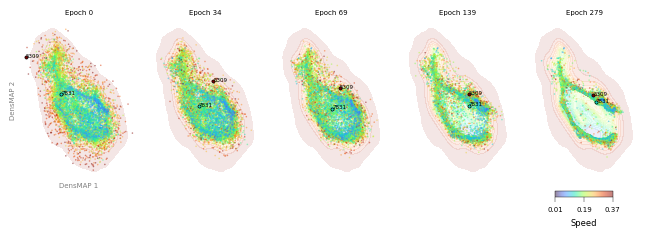

In [372]:
# Visualize the evolution of data in the embedding space
import matplotlib.cm as cm
import matplotlib.colors as colors

# Calculate limits for plotting based on the initial state
x_min, x_max = data[0, :, 0].min(), data[0, :, 0].max()
y_min, y_max = data[0, :, 1].min(), data[0, :, 1].max()
pad = 0.5

# Choose one high-speed and one medium-speed neuron to highlight
num_neurons = data.shape[1]
sorted_speed_indices = np.argsort(speeds_np[0])
high_speed_idx = sorted_speed_indices[-1] # Fastest neuron
medium_speed_idx = sorted_speed_indices[num_neurons // 2 -100] # Medium speed neuron
highlight_neuron_indices = [high_speed_idx, medium_speed_idx]

# Define colormap and normalization for speeds
norm = colors.Normalize(vmin=speeds_np.min(), vmax=speeds_np.max())
cmap = cm.get_cmap('turbo')
h_colors = [cmap(norm(speeds_np[0, idx])) for idx in highlight_neuron_indices]

# Actual trajectories for the highlighted neurons
actual_trajectories_highlight = data[:, highlight_neuron_indices, :]

fig, axes = plt.subplots(1, 5, figsize=(8, 2))

# Define time points to display (e.g., concentrated at the beginning)
num_subplots = 5
T = data.shape[0] - 1
time_indices = np.array([0, T // 8, T // 4, T // 2, T]).astype(int)

for i, t_idx in enumerate(time_indices):
    ax = axes[i]
    
    # Plot background density
    sns.kdeplot(x=data[0, :, 0], y=data[0, :, 1], fill=True, ax=ax, cmap='turbo_r', alpha=0.1, zorder=0, thresh=0.005, levels=20)
    
    # Plot all neurons at the current time point
    sns.scatterplot(x=data[t_idx, :, 0], y=data[t_idx, :, 1], hue=speeds_np[0], palette='turbo', hue_norm=(0,.3), s=1, alpha=.5, ax=ax, legend=False, edgecolor=None)
    
    # Plot highlighted neurons' current positions
    for h_i, h_idx in enumerate(highlight_neuron_indices):
        sns.scatterplot(x=[actual_trajectories_highlight[t_idx, h_i, 0]], y=[actual_trajectories_highlight[t_idx, h_i, 1]], color=h_colors[h_i], s=5, edgecolor='black', zorder=5, linewidth=.5, ax=ax, legend=False)
        ax.text(actual_trajectories_highlight[t_idx, h_i, 0], actual_trajectories_highlight[t_idx, h_i, 1], f'{h_idx}', fontsize=4, color='k')
    
    # Set axis limits
    ax.set_xlim(x_min - pad, x_max + pad)
    ax.set_ylim(y_min - pad, y_max + pad)
    
    # Overlay data[t,:,:] colored by speeds_np[t]
   

    ax.set_title(f'Epoch {t_idx}',color='k',fontsize = 5)
    if i == 0:
        ax.set_xlabel('DensMAP 1',fontsize = 5,color='gray')
    else:
        ax.set_xlabel('')
    if i == 0:
        ax.set_ylabel('DensMAP 2',fontsize = 5,color='gray')
    else:
        ax.set_ylabel('')
    
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)

# Increase horizontal space between subplots
fig.subplots_adjust(wspace=.1)

# Add a colorbar for the speeds
# Positioning colorbar horizontally under the last subplot
# Get position of the last subplot
last_ax_pos = axes[-1].get_position()
cbar_ax = fig.add_axes([last_ax_pos.x0 + last_ax_pos.width * 0.25, last_ax_pos.y0 - 0.1, last_ax_pos.width * 0.5, 0.03])
sm = plt.cm.ScalarMappable(cmap='turbo', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, label='Speed', ticks=np.linspace(speeds_np.min(), speeds_np.max(), 3), alpha=0.5, orientation='horizontal')
cbar.outline.set_linewidth(0.3)
cbar.ax.set_xticklabels([f'{t:.2f}' for t in np.linspace(speeds_np.min(), speeds_np.max(), 3)])
cbar.ax.tick_params(labelsize=5, width=0.3)
cbar.set_label('Speed', fontsize=6)

# Save the figure
os.makedirs('../Figures', exist_ok=True)
plt.savefig('../Figures/evolution.png', bbox_inches='tight', dpi=300)

#plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.show()

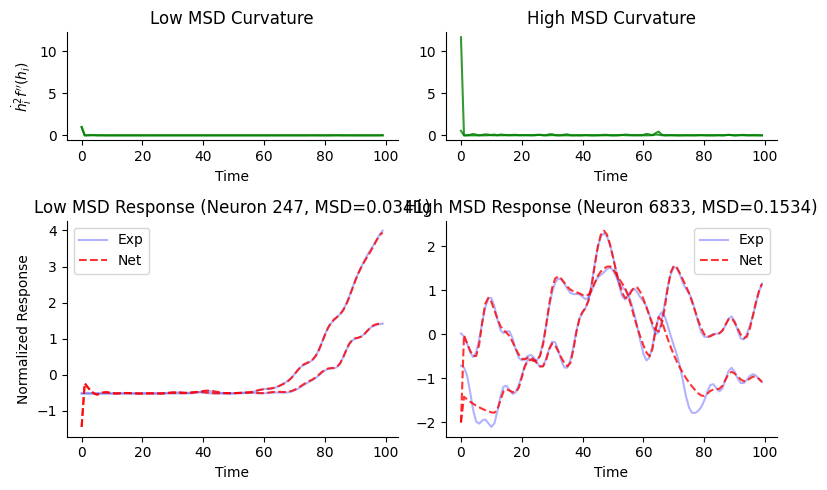

In [371]:
# Identify parameters for RNN prediction
# Based on cell 271: u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
u_val = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
dt_val = 1
steps_val = 100

# 1. Experimental response (mean across pseudo-trials)
# pseudo_response_tensor shape: (pseudo_trials, conditions, time, neurons)
exp_response = np.mean(pseudo_response_tensor, axis=0) # (conditions, time, neurons)

# 2. Predicted response from the 'net' model
net.eval()
with torch.no_grad():
    # net forward: (u, dt, steps) -> (batch, time, neurons)
    # u should be (2, 1) as seen in cell 271
    pred_response_torch = net(u_val.unsqueeze(1), dt_val, steps_val)
    pred_response = pred_response_torch.cpu().numpy() # (2, 100, neurons)

# 3. Normalize both responses (Z-score over conditions and time for each neuron)
def normalize_response(resp):
    # resp shape: (conditions, time, neurons)
    mean = np.mean(resp, axis=(0, 1), keepdims=True)
    std = np.std(resp, axis=(0, 1), keepdims=True) + 1e-8
    return (resp - mean) / std

exp_response_norm = normalize_response(exp_response)
pred_response_norm = normalize_response(pred_response)

# 4. Select two neurons: one with low MSD and one with high MSD
low_msd_idx = np.argsort(msd_data)[40]
high_msd_idx = np.argsort(msd_data)[-3000]

# 5. Plot the comparison
fig = plt.figure(figsize=(8, 5))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 2])

# Calculate curvature for all neurons
# pred_curvature shape: (batch, steps, neurons)
pred_curvature, _ = get_curvature(net, u_val.unsqueeze(1), dt_val, steps_val)

# Determine global y-limits for curvature plots
curvature_neurons = [low_msd_idx, high_msd_idx]
c_min = pred_curvature[:, :, curvature_neurons].min()
c_max = pred_curvature[:, :, curvature_neurons].max()
# Add a small buffer
c_range = c_max - c_min
c_min -= 0.05 * c_range
c_max += 0.05 * c_range

for idx, neuron_idx in enumerate(curvature_neurons):
    msd_val = msd_data[neuron_idx]
    title_prefix = "Low MSD" if idx == 0 else "High MSD"
    
    # --- Top Row: Curvature Plot ---
    ax_curv = fig.add_subplot(gs[0, idx])
    # Plot curvature for all conditions
    for c in range(pred_curvature.shape[0]):
        ax_curv.plot(pred_curvature[c, :, neuron_idx], color='green', alpha=0.8)
    
    ax_curv.set_title(f"{title_prefix} Curvature")
    ax_curv.set_ylim(c_min, c_max)
    if idx == 0:
        ax_curv.set_ylabel("$\dot{h}_i^2 f''(h_i)$")
    ax_curv.set_xlabel("Time")
    sns.despine(ax=ax_curv)

    # --- Bottom Row: Response Plot ---
    ax_resp = fig.add_subplot(gs[1, idx])
    
    # Plot experimental response for all conditions
    for c in range(exp_response_norm.shape[0]):
        ax_resp.plot(exp_response_norm[c, :, neuron_idx], color='blue', alpha=0.3, label='Exp' if c==0 else "")
    
    # Plot predicted response for all conditions
    for c in range(pred_response_norm.shape[0]):
        ax_resp.plot(pred_response_norm[c, :, neuron_idx], color='red', linestyle='--', alpha=0.8, label='Net' if c==0 else "")
    
    ax_resp.set_title(f"{title_prefix} Response (Neuron {neuron_idx}, MSD={msd_val:.4f})")
    ax_resp.set_xlabel("Time")
    if idx == 0:
        ax_resp.set_ylabel("Normalized Response")
    ax_resp.legend()
    sns.despine(ax=ax_resp)

plt.tight_layout()
os.makedirs('../Figures', exist_ok=True)
plt.savefig('../Figures/neuron_fit_comparison.png', dpi=300)
plt.show()

In [ ]:
data.shape

In [ ]:
data.shape